# Future field with a spatial receptive field and convergent remapping

Does figure 4's future-field model still produce the relational spectrum of the example neurons when
the receptive field depends on **distance** (a 2-D Gaussian in space, not a von Mises in direction)
and remapping is **convergent** (Zirnsak et al., 2014: remapped fields are pulled toward the saccade
target)? The model is `ff_distance_lib.DistanceFutureFieldModel`; its docstring has the equations.

**The figure** (5 rows × 5 neurons). Columns: `figure_4/figure_example_neurons.ipynb`'s `UNITS`, read
from that notebook. Each ring shows the stimuli that drive the neuron most at each inter-object
angle in `SEPARATIONS`, in `figure_example_neurons`' style.

1. **Data**: the neuron's measured maximum chords (`figure_example_neurons`' procedure).
2. **Future field (figure 4)**: figure 4's cached all-trial fit of its future-field model
   (direction-only von Mises receptive field, perfect remapping).
3. – 5. **Distance future field** at each convergence κ in `CONVERGENCES` (0 = perfect remapping,
   1 = every future field on the saccade target), with the receptive-field centre fixed at
   `RF_ECC` ring radii. Each is fit to the neuron's 2-object trials by figure 4's optimiser, with
   κ and `RF_ECC` held fixed and the other five parameters free.

Model rows draw every local maximum of the noise-free predicted rate, up to `SEPARATIONS[sep]` per
separation (as `figure_example_model_neurons.ipynb`). The printed table gives each fit's ΔLL, the
all-trial log-likelihood per trial above a constant-rate model (nats/trial), so rows can be
compared for fit.

The figure is saved to `OUTPUT`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
common.set_style()
import ff_distance_lib as fdl          # puts figure_4/ on sys.path
import data_lib
import example_neurons_lib as enl
import tuning_lib

# ══ The model ═════════════════════════════════════════════════════════════════
RF_ECC = 1.5                     # receptive-field centre, in ring radii (held fixed in every fit)
CONVERGENCES = (0.0, 1 / 4, 1 / 2)   # κ for rows 3-5: 0 = perfect remapping, 1 = on target

# ══ The figure: example neurons × models ══════════════════════════════════════
OUTPUT = 'distance_future_field_examples.pdf'
UNITS = fdl.example_units()      # (subject, session, unit, rotation_deg), from figure_example_neurons
SEPARATIONS = {180: 1, 130: 2, 80: 2}           # inter-object angle -> how many chords
N_DENSE = 180                                   # data row: chord midpoints sampled (2 deg)
MIN_PROMINENCE_FRAC = 0.1                       # data row: peak prominence (fraction of range)
WINDOW_DEG = data_lib.SIMILARITY_WINDOW_DEG
SMOOTH_DEG = data_lib.LINE_SMOOTH_DEG_2OBJ
FIGSIZE_EXAMPLES = (8.2, 10.6)   # (width, height), inches
ROW_LABEL_X = -0.12              # row labels' x, in the first column's axes fraction

# ══ Drawing ═══════════════════════════════════════════════════════════════════
RING_RADIUS = 0.43               # in axes fractions, as figure 2/4's rings
CHORD_LW = 2.0
DOT_SIZE = 14
TITLE_PAD = -2.0
MAX_COLOR = tuning_lib.FIRING_RATE_CMAP(1.0)

## Fits and maximum chords

In [2]:
def model_label(kappa):
    return f'Convergence = {kappa:.2f}'


rows = ['Data', 'Future field\n(figure 4)'] + [model_label(k) for k in CONVERGENCES]
grid = [[None] * len(UNITS) for _ in rows]      # (chords, ΔLL or None)
table = []
for col, (s, ses, u, _) in enumerate(UNITS):
    ch, _ = enl.empirical_chords(s, ses, u, SEPARATIONS, N_DENSE, WINDOW_DEG, SMOOTH_DEG,
                                 MIN_PROMINENCE_FRAC)
    grid[0][col] = (ch, None)

    m4, p4, dll4 = fdl.figure4_fit(s, ses, u)
    grid[1][col] = (enl.drawn_model_chords(m4, p4, SEPARATIONS)[0], dll4)
    table.append(dict(unit=u, model='figure 4 FF', dll=dll4, theta_deg=np.degrees(p4['theta']),
                      width=p4['width'], a_ret=p4['amplitude_retinotopic'],
                      a_ff=p4['amplitude_remapped'], baseline=p4['baseline']))

    for r, kappa in enumerate(CONVERGENCES, start=2):
        model = fdl.DistanceFutureFieldModel(RF_ECC, kappa)
        p, dll = fdl.cached_fit(s, ses, u, model)
        grid[r][col] = (enl.drawn_model_chords(model, p, SEPARATIONS)[0], dll)
        table.append(dict(unit=u, model=f'distance κ={kappa:.2f}', dll=dll,
                          theta_deg=np.degrees(p['theta']) % 360, width=p['width'],
                          a_ret=p['amplitude_retinotopic'], a_ff=p['amplitude_remapped'],
                          baseline=p['baseline']))

table = pd.DataFrame(table)
# width: figure 4's von Mises width parameter; the distance model's σ in ring radii.
print(table.round(3).to_string(index=False))

  fit Perle/2022-06-16 unit 89  ρ=1.5 κ=0.00: ΔLL 2.877 nats/trial
  fit Perle/2022-06-16 unit 89  ρ=1.5 κ=0.25: ΔLL 2.876 nats/trial
  fit Perle/2022-06-16 unit 89  ρ=1.5 κ=0.50: ΔLL 2.876 nats/trial
  fit Perle/2022-06-09 unit 78  ρ=1.5 κ=0.00: ΔLL 4.603 nats/trial
  fit Perle/2022-06-09 unit 78  ρ=1.5 κ=0.25: ΔLL 4.599 nats/trial
  fit Perle/2022-06-09 unit 78  ρ=1.5 κ=0.50: ΔLL 4.557 nats/trial
  fit Perle/2022-06-11 unit 129  ρ=1.5 κ=0.00: ΔLL 0.460 nats/trial
  fit Perle/2022-06-11 unit 129  ρ=1.5 κ=0.25: ΔLL 0.481 nats/trial
  fit Perle/2022-06-11 unit 129  ρ=1.5 κ=0.50: ΔLL 0.477 nats/trial
  fit Perle/2022-06-10 unit 158  ρ=1.5 κ=0.00: ΔLL 3.105 nats/trial
  fit Perle/2022-06-10 unit 158  ρ=1.5 κ=0.25: ΔLL 2.990 nats/trial
  fit Perle/2022-06-10 unit 158  ρ=1.5 κ=0.50: ΔLL 2.695 nats/trial
  fit Perle/2022-06-11 unit 126  ρ=1.5 κ=0.00: ΔLL 3.760 nats/trial
  fit Perle/2022-06-11 unit 126  ρ=1.5 κ=0.25: ΔLL 3.358 nats/trial
  fit Perle/2022-06-11 unit 126  ρ=1.5 κ=0.50: ΔLL 2.6

saved distance_future_field_examples.pdf


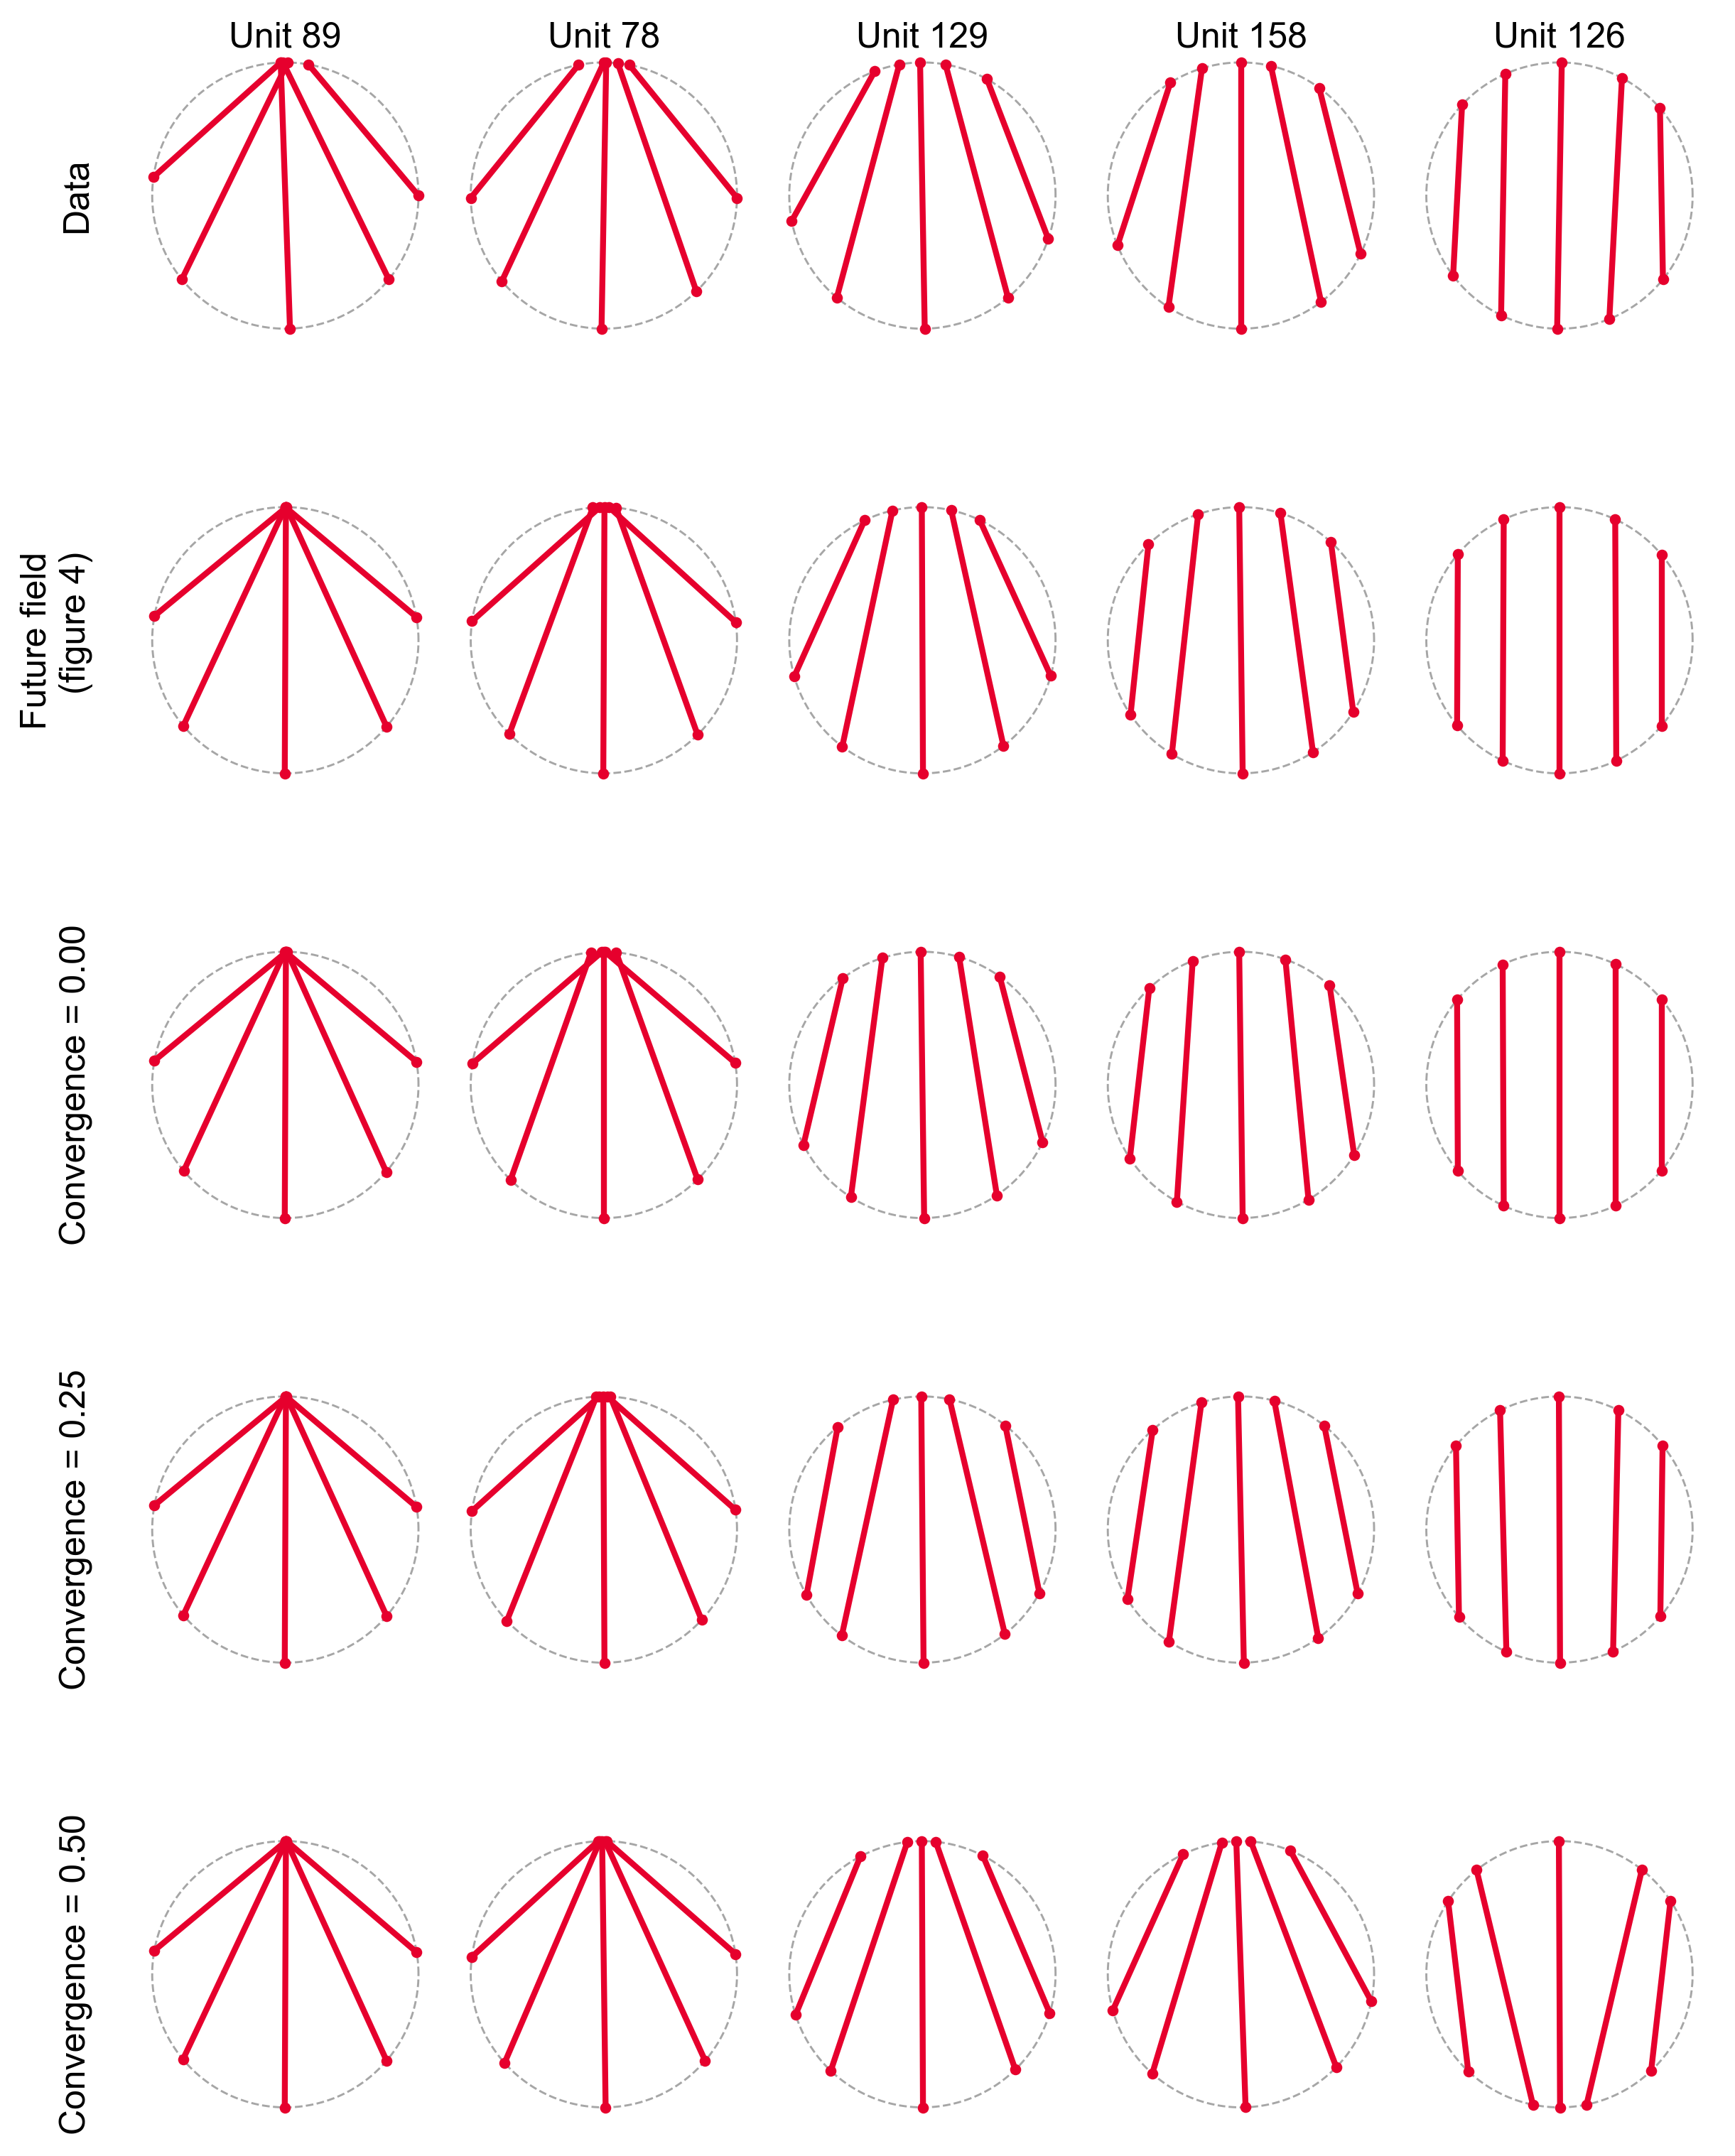

In [3]:
def draw_ring(ax, chords, rot_rad=0.0):
    tuning_lib.pl._prep_stim_ax(ax, RING_RADIUS)
    ax.lines[-1].remove()                                  # no fixation cross: it is _prep_stim_ax's last line
    for a, c, *_ in chords:
        x = 0.5 + RING_RADIUS * np.cos(np.array([a, c]) + rot_rad)
        y = 0.5 + RING_RADIUS * np.sin(np.array([a, c]) + rot_rad)
        ax.plot(x, y, color=MAX_COLOR, lw=CHORD_LW, solid_capstyle='round', zorder=3)
        ax.scatter(x, y, s=DOT_SIZE, color=MAX_COLOR, zorder=4, linewidths=0)


fig, axes = plt.subplots(len(rows), len(UNITS), figsize=FIGSIZE_EXAMPLES, squeeze=False)
for r, label in enumerate(rows):
    for col, (s, ses, u, deg) in enumerate(UNITS):
        ax = axes[r, col]
        ch, _ = grid[r][col]
        draw_ring(ax, ch, np.radians(deg))
        if r == 0:
            ax.set_title(f'Unit {u}', fontsize=12, pad=TITLE_PAD, y=1.0)
    axes[r, 0].text(ROW_LABEL_X, 0.5, label, transform=axes[r, 0].transAxes, rotation=90,
                    ha='right', va='center', fontsize=12)
fig.tight_layout(h_pad=0.6, w_pad=0.3)
common.save(fig, OUTPUT)
plt.show()